# ITCHI v0.2.1: cómo determina el peligro (esquemas, sin datos)

Este notebook explica, figura por figura, cómo ITCHI v0.2.1 convierte lluvia, viento y radios en una clase de peligro, y qué cambia con las dos propuestas del avance: el **máximo de lluvia en el P95** de 6 h en lugar del P99 (caso 1) y el **viento absoluto homologado con Saffir-Simpson** con la cola cortada en 12 m/s (caso 2). Los casos reales están en los notebooks 12 (lluvia), 13 (viento) y 14 (deslizamientos).

No usa datos: todas las figuras salen de las funciones de la librería (`itchi.precipitation`, `itchi.parametric_radii`, `itchi.wind`, `itchi.pipeline`) con los percentiles medianos de México de `docs/verification_v02.md` (tabla 1).

| Figura | Qué muestra | Pregunta que contesta |
|---|---|---|
| A1 | Diagrama de flujo | ¿Qué entra, qué se calcula y en qué orden? |
| A2 | H_P contra P6, máximo en P99 y en P95 | ¿Qué hace mover el máximo al P95? |
| A3 | Clase de H_P en el plano P6 × A72 | ¿Cuándo cuenta el suelo saturado? |
| A7 | Clase de ITCHI en el plano (H_P, H_W) | ¿Cómo se combinan lluvia y viento? |
| A4 | H_W contra viento local, tres variantes | ¿Por qué el viento relativo a Vmax infla las tormentas débiles? |
| A5 | H_W contra distancia, tres intensidades | ¿Qué cambia en el espacio con el corte en 12 m/s y Saffir-Simpson? |
| A6 | Snapshot sintético con el pipeline completo | ¿Qué región, qué variable y qué escala deciden cada píxel? |
| A8 | De píxel a municipio | ¿Qué valor recibe un municipio? |

Las figuras se guardan en `outputs/figures/avance_v021/esquemas/`.

## 0. Configuración

In [ ]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

from itchi.config import get_project_root

ROOT = get_project_root()
sys.path.insert(0, str(ROOT / "scripts"))
import figuras_v021 as F      # noqa: E402

FIG = ROOT / "outputs" / "figures" / "avance_v021" / "esquemas"
FIG.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()


pd.Series({k.replace("Q", "P"): v for k, v in F.Q_MEX[6].items()}, name="mm en 6 h (mediana de México)").to_frame().T

## A1. Diagrama de flujo

**Cómo leerlo.** De izquierda a derecha:
1. **Entradas.** Lluvia observada de MSWEP V3 en ventanas de 6 h que terminan en el tiempo sinóptico T: P6 es la lluvia de las últimas 6 h, R24 la de las últimas 24 h y A72 la de las 72 h anteriores a P6 (antecedente, no se traslapa con P6). La climatología da los percentiles de cada duración en cada píxel. La trayectoria da centro, Vmax, RMW y R34; ROCLOUD da el tamaño de la nubosidad.
2. **Peligros físicos.** H_P (lluvia) y H_W (viento), cada uno en [0, 1].
3. **Regiones.** Dentro de R34 (directa) cuentan el viento completo y la lluvia. Entre R34 y el radio de atribución (indirecta) cuenta la lluvia y la cola de viento. Fuera, el ciclón no aporta.
4. **ITCHI y clase.** Unión probabilística y cinco clases de 0.2.
5. **Agregación.** Máximo en el tiempo (evento) y máximo sobre los píxeles del municipio.

En rojo, lo que cambia en este avance. Fuera de esos tres recuadros, todo es v0.2.0 sin cambios.

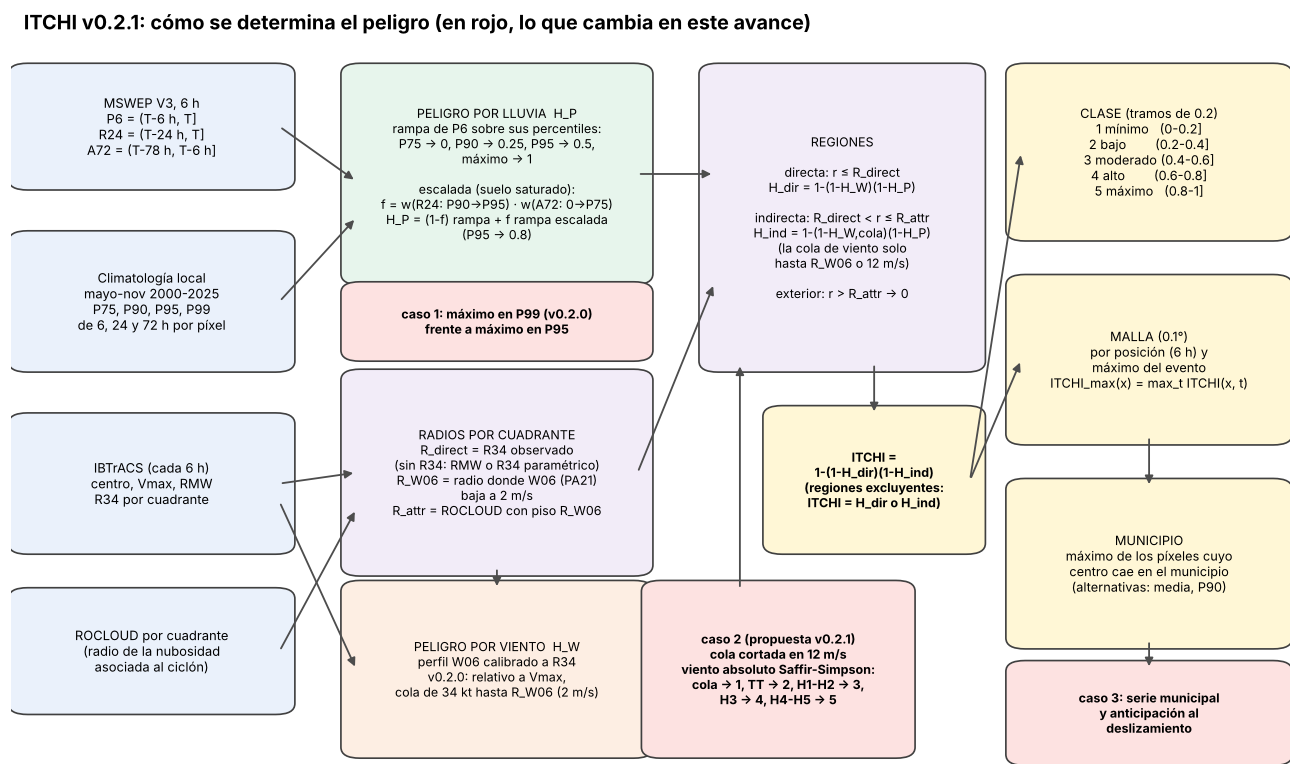

In [ ]:
guardar(F.fig_a1_flujo(), "A1_flujo")

## A2. Peligro por lluvia: máximo en P99 (v0.2.0) frente a máximo en P95

**v0.2.0.** La rampa de P6 tiene nodos en P75 (0), P90 (0.25), P95 (0.5) y P99 (1). La escalada por persistencia y suelo saturado usa un peso f = w(R24) · w(A72):
- w(R24) sube de 0 en el P90 de 24 h a 1 en el P95 de 24 h;
- w(A72) sube de 0 en 0 mm a 1 en el P75 de 72 h (suelo saturado).

Con f = 1, el nodo inmediatamente debajo del máximo (P95) sube de 0.5 a 0.8.

**Máximo en P95.** Misma lógica recorrida una clase: P75 → 0, P90 → 0.25, **P95 → 1**, y la escalada sube el nodo inmediatamente debajo del máximo, que ahora es el **P90, a 0.8** (`precipitation.PRECIP_MATRIX_V02_P95`). Si solo se cambiara el máximo, la escalada no tendría efecto, porque el P95 ya vale 1. Es la idea de M1 del Bloque 1 (allí el P90 subía hasta 1 y la rampa base tenía P90 → 0.5).

**Cómo leerla.**
- **Panel 1 (sin escalada).** Hasta el P90 las dos curvas son iguales. Entre P90 y P95 la curva naranja sube de 0.25 a 1: las clases 3, 4 y 5 caben en ese tramo de ~9 mm.
- **Panel 3 (suelo saturado).** La curva naranja llega a 0.8 en el P90, así que la clase 5 empieza en el P90 de 6 h (≈ 20 mm), frente al P95 (≈ 29 mm) en v0.2.0.
- **Consecuencia.** El P95 como máximo sube el peligro de toda la lluvia por encima del P90, con o sin antecedente, y conserva el efecto del suelo saturado (lo adelanta una clase).

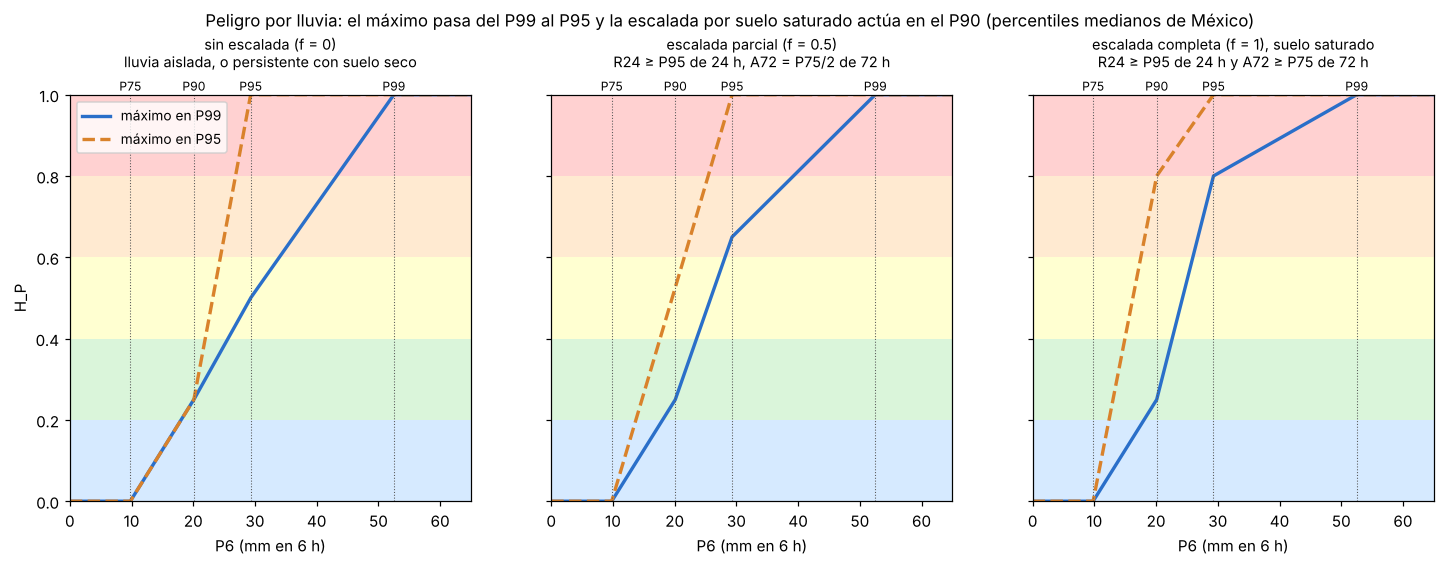

In [ ]:
guardar(F.fig_a2_lluvia_rampas(), "A2_lluvia_rampas")

**P6 (mm en 6 h) a partir del cual H_P entra en cada clase** (mediana de México; "suelo saturado" = R24 ≥ P95 de 24 h y A72 ≥ P75 de 72 h).

**Cómo leerla.**
- **Clase 5.** Sin escalada baja de 43.2 mm (casi el P99) a 26.8 mm; con suelo saturado, de 29.3 mm (P95) a 20.1 mm (P90).
- **Clase 4.** Sin escalada pasa de 9.3 mm de ancho (33.9–43.2) a 2.4 mm (24.4–26.8). Queda más estrecha, pero no desaparece.
- **Clases 1 y 2.** No cambian sin escalada. Con suelo saturado, la clase 2 empieza en 12.4 mm en lugar de 18.0: la escalada en el P90 también sube la lluvia moderada.

In [ ]:
F.tabla_umbrales_lluvia()

## A3. Clase de H_P en el plano P6 × A72

Cada panel es una combinación de lluvia de 6 h (eje x) y antecedente de 72 h (eje y). La fila de arriba supone que solo llovió en las últimas 6 h (R24 = P6); la de abajo, lluvia persistente (R24 ≥ P95 de 24 h). La línea discontinua es A72 = P75 de 72 h, el suelo saturado.

**Cómo leerla.**
- **Fila de abajo, columna P99.** La frontera de la clase 5 baja del P99 (≈ 43 mm de P6) al P95 (29 mm) conforme A72 se acerca a P75. Esa es la «rampa con suelo saturado» de v0.2.0.
- **Fila de abajo, columna P95.** La misma frontera baja del P95 (≈ 27 mm) al P90 (20 mm). El suelo saturado sigue moviendo la frontera, una clase antes.
- **Fila de arriba.** Con R24 = P6 el antecedente actúa solo cuando la ventana de 6 h supera por sí sola el P90 de 24 h (≈ 32 mm). En la versión P95 eso ocurre ya en clase 5, así que la fila de arriba depende solo de P6.

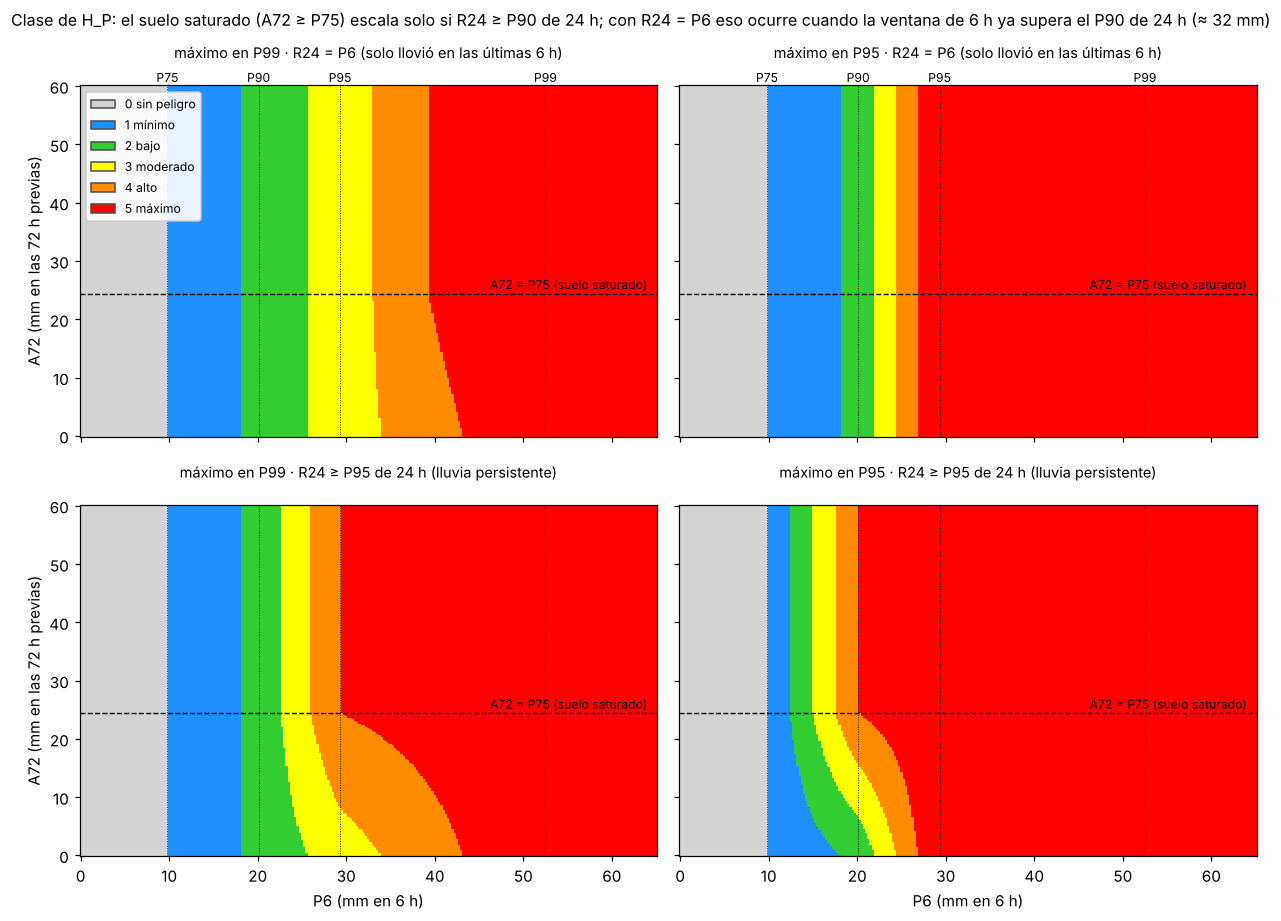

In [ ]:
guardar(F.fig_a3_lluvia_plano(), "A3_lluvia_plano")

## A7. Cómo se combinan lluvia y viento

ITCHI = 1 − (1 − H_W)(1 − H_P) en cada región (en la indirecta, H_W es la cola). Es la probabilidad de que ocurra al menos uno de dos sucesos independientes con probabilidades H_W y H_P.

**Cómo leerla.**
- Las fronteras de clase son curvas, no rectas: ITCHI nunca es menor que el mayor de los dos peligros.
- Dos peligros moderados se refuerzan: H_P = H_W = 0.5 da ITCHI = 0.75 (clase 4).
- Con viento de clase 1 (H_W ≤ 0.2), una lluvia de clase 2 puede subir a la clase 3. Por eso la cola de viento de v0.2.0, que cubre todo el radio R_W06, sube de clase a mucha lluvia moderada. Es el motivo del corte en 12 m/s (caso 2).

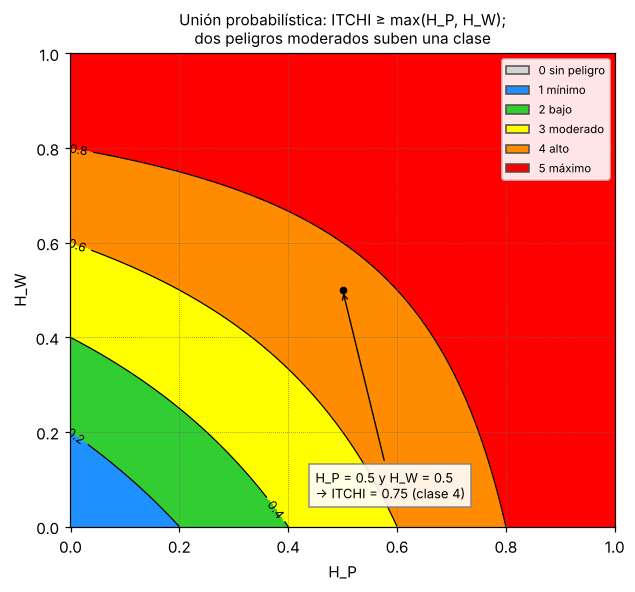

In [ ]:
guardar(F.fig_a7_combinacion(), "A7_combinacion")

## A4. Peligro por viento contra viento local

**v0.2.0** normaliza con la Vmax de cada tormenta: dentro de R34, H_W = 0.2 + 0.8 (V − 34)/(Vmax − 34). Fuera de R34 hay una cola lineal de 0 (en el viento de R_W06, 2 m/s) a 0.2 (en 34 kt).

**Propuesta v0.2.1** (`wind_hazard_scale = "saffir_simpson"`): H_W depende solo del viento local, con nodos que ponen cada categoría Saffir-Simpson en una clase de ITCHI:

| Viento local (kt, sostenido 1 min) | Categoría | H_W | Clase |
|---|---|---|---|
| 23.3 (12 m/s) a 34 | por debajo de tormenta tropical (cola) | 0 → 0.2 | 1 mínimo |
| 34 a 63 | tormenta tropical | 0.2 → 0.4 | 2 bajo |
| 64 a 95 | huracán 1 y 2 | 0.4 → 0.6 | 3 moderado |
| 96 a 112 | huracán 3 (mayor) | 0.6 → 0.8 | 4 alto |
| ≥ 113 | huracán 4 y 5 | 0.8 → 1 (1 desde 137 kt) | 5 máximo |

**Cómo leerla.**
- **Paneles 1 y 2.** El punto final de cada recta es la Vmax de la tormenta, y ahí H_W = 1. Una tormenta tropical de 45 kt llega a la clase 5 con 45 kt; un huracán de 140 kt necesita 140 kt para lo mismo. La clase dice qué tan cerca del centro está el píxel, no qué tan fuerte es el viento.
- **Panel 3.** Una sola curva para todas las tormentas: 45 kt es clase 2 en cualquier ciclón.
- **Línea discontinua.** Fin de la cola. Con 2 m/s la cola empieza casi en calma; con 12 m/s, en viento de Beaufort 6.

Los nodos son una propuesta, no una calibración. La agrupación (H1–H2 juntos, H4–H5 juntos) se puede cambiar en `wind.saffir_simpson_nodes` de la configuración sin tocar código. Las clases son (inferior, superior], así que un viento exactamente en un límite de categoría (por ejemplo 64 kt) cae en la clase de abajo; eso solo ocurre sobre una isolínea.

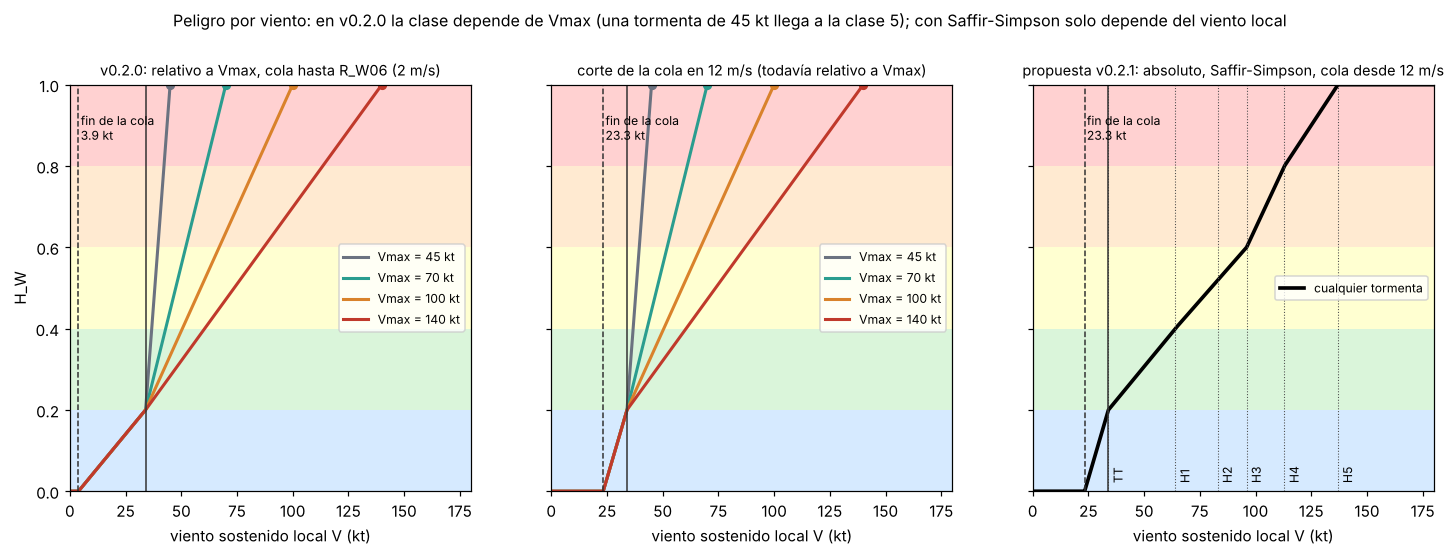

In [ ]:
guardar(F.fig_a4_viento_escalas(), "A4_viento_escalas")

## A5. Peligro por viento contra distancia al centro

Perfil W06 (configuración PA21) para tres intensidades a 18° N, con R34 paramétrico. Las líneas verticales son el RMW, R34, el radio donde el viento baja a 12 m/s y R_W06 (2 m/s).

**Cómo leerla.**
- **Corte en 12 m/s (verde).** Igual que v0.2.0 dentro de R34; la cola termina en el radio de 12 m/s en lugar de R_W06. En la tormenta tropical la cola pasa de ~800 km a ~250 km.
- **Saffir-Simpson (rojo).** En la tormenta tropical el máximo baja de 1 a ~0.3 (clase 2); en el huracán categoría 2, de 1 a ~0.55 (clase 3). En el categoría 5 casi no cambia, porque v0.2.0 ya normalizaba con una Vmax alta.
- **Ojo.** Dentro del RMW el viento del perfil baja a cero. v0.2.0 le asigna 0.2 (piso de la región directa). La propuesta le asigna el peligro de Vmax, porque la pared del ojo pasa por el píxel dentro de la ventana de 6 h.

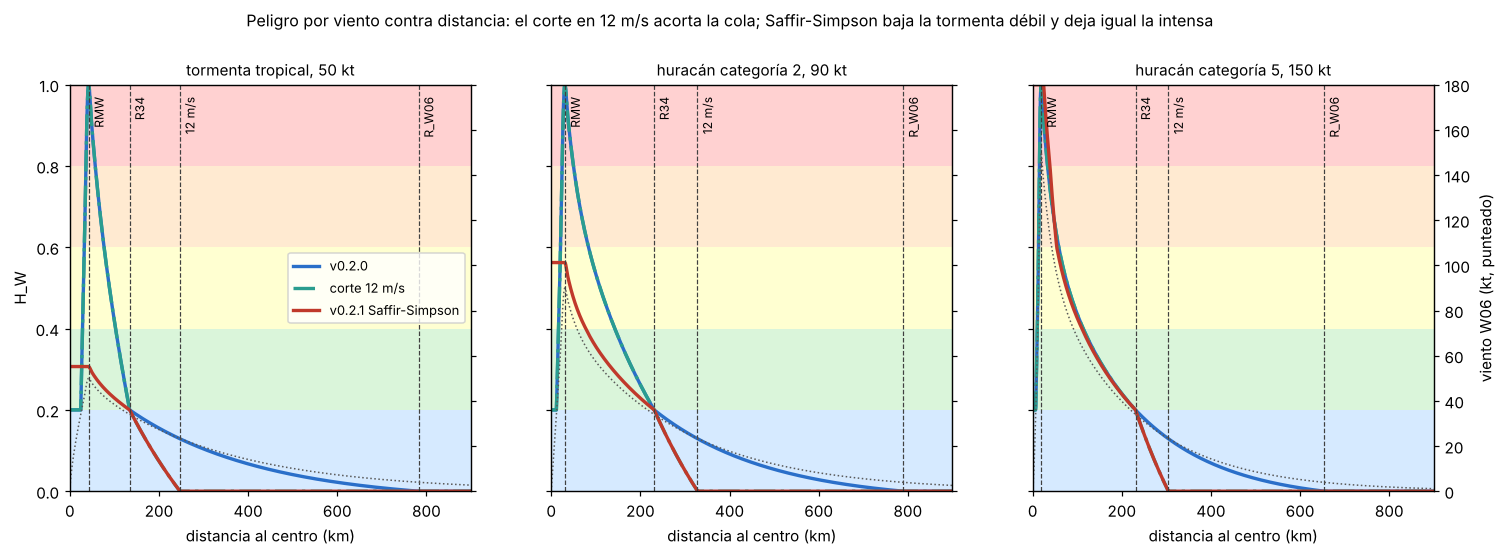

In [ ]:
guardar(F.fig_a5_viento_radial(), "A5_viento_radial")

## A6. Un snapshot sintético con el pipeline completo

`compute_itchi_snapshot_v02` sobre campos inventados: huracán de 100 kt, R34 asimétrico, banda de lluvia en espiral y suelo húmedo al noroeste. ROCLOUD es mayor que R_W06 en NE y SE, falta en SO y es menor que R_W06 en NO.

**Cómo leerla.**
- **Regiones.** El radio de atribución (magenta) es ROCLOUD donde existe y es mayor que R_W06; si no, R_W06. La lluvia cuenta hasta ese radio; la cola de viento de v0.2.0, solo hasta R_W06 (naranja).
- **H_P.** Mismo campo con máximo en P99 y en P95: con P95 la espiral se satura (azul oscuro) en más área.
- **H_W.** v0.2.0 llena todo el círculo de R_W06 con una cola débil; Saffir-Simpson termina en el radio de 12 m/s.
- **Clase de ITCHI.** Con v0.2.0, todo el círculo de R_W06 queda al menos en clase 1 por la cola. Con la propuesta, fuera del radio de 12 m/s solo hay peligro donde llueve por encima del P75.

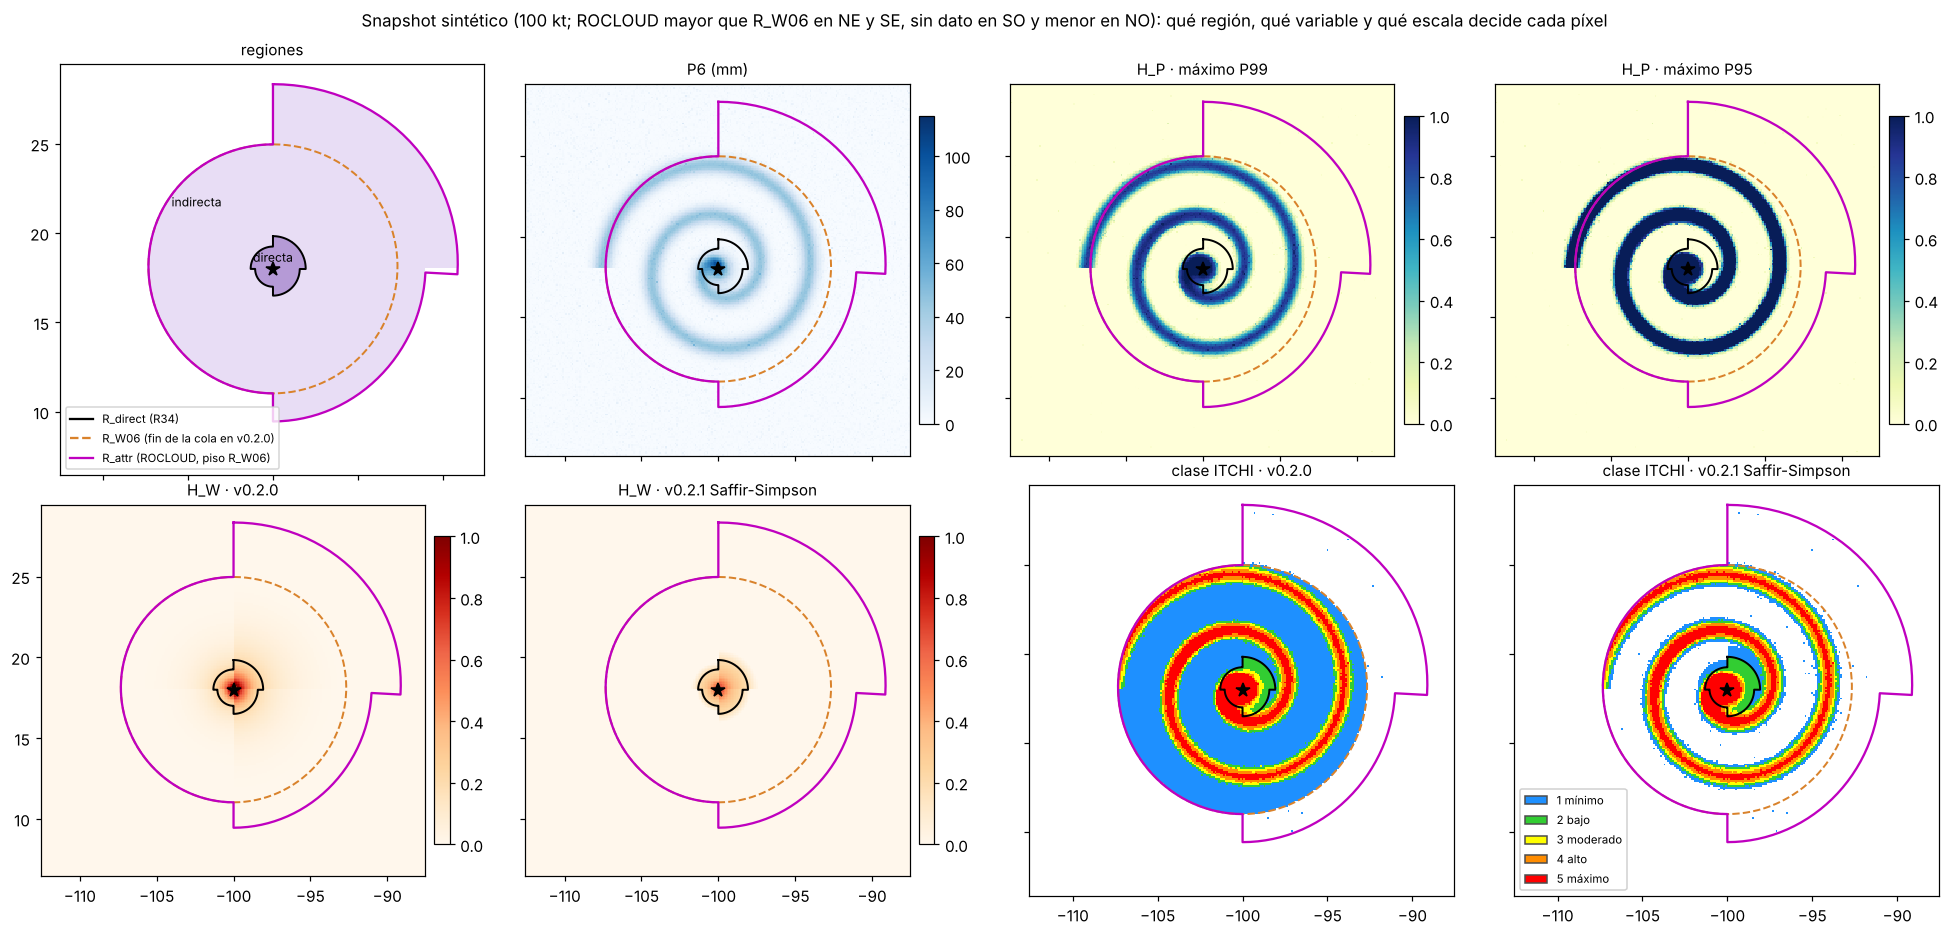

In [ ]:
guardar(F.fig_a6_regiones(), "A6_regiones")

## A8. De píxel a municipio

El valor municipal es el **máximo** de ITCHI sobre los píxeles de 0.1° cuyo centro cae dentro del municipio. Un municipio que no contiene ningún centro de píxel toma el píxel más cercano a su punto representativo (`itchi.declaratorias_6h.municipio_pixels`). Es la misma regla de los notebooks 05–08 y del Bloque 1.

**Cómo leerla.**
- **A (grande).** El núcleo de lluvia ocupa una esquina. Con el máximo, todo el municipio queda en clase 5; con la media, en clase 2. Es la diferencia entre «hubo peligro máximo en alguna parte del municipio» y «el peligro típico del municipio».
- **C y D (pequeños).** Tienen uno o pocos píxeles, así que los tres estadísticos coinciden. Su valor depende de un solo píxel de 11 km.
- **Consecuencia para los mapas.** Con el máximo, el mapa municipal **siempre** tiene clases iguales o mayores que el promedio de los píxeles, y los municipios grandes de la sierra (Guerrero, Oaxaca, Durango) se ven más afectados que en la malla. La elección del estadístico es una decisión pendiente del plan v0.3 (decisión 4); el código acepta `"max"`, `"mean"` y `"p90"` (`ConfigV021.municipal_stat`).

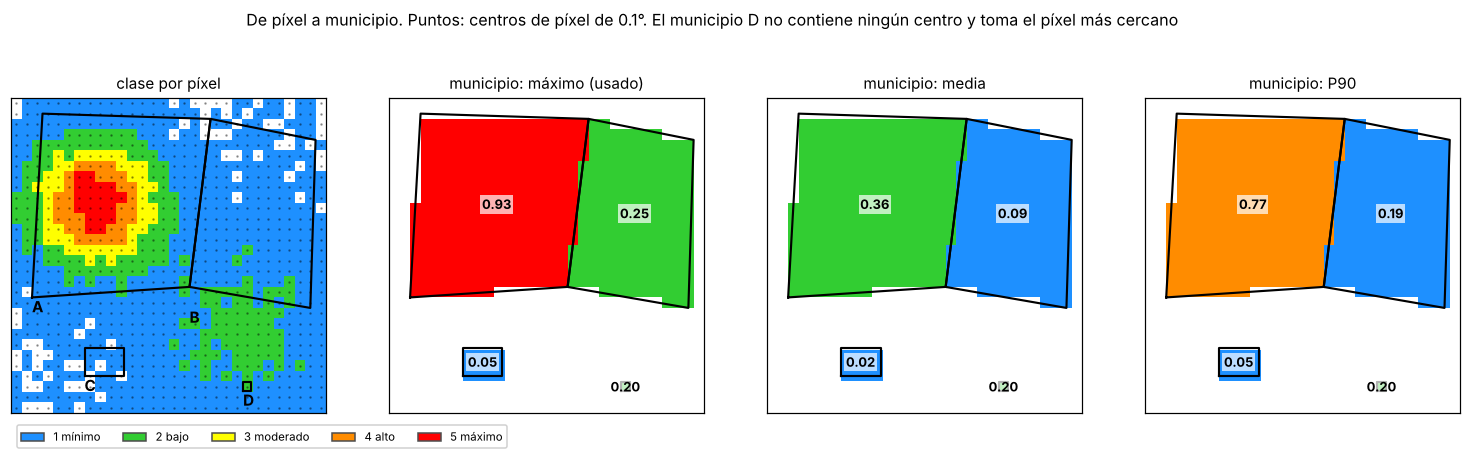

In [ ]:
guardar(F.fig_a8_municipio(), "A8_municipio")

## Resumen para la discusión

| Tema | v0.2.0 | Propuesta v0.2.1 | Efecto esperado (de estos esquemas) | Decisión pendiente |
|---|---|---|---|---|
| Máximo de lluvia | P99 de 6 h | P95 de 6 h | Clase 5 desde ~27 mm sin escalada y desde el P90 con suelo saturado; clase 4 de 2.4 mm de ancho | El Bloque 1 no encontró mejora en discriminación con P95 como máximo: ¿se adopta por razones operativas? |
| Suelo saturado | Escalada R24 × A72 en el P95 | La misma escalada, en el P90 | Conserva el efecto y lo adelanta una clase; sube también la lluvia moderada | ¿P90 → 0.8 o P90 → 1 (M1 del Bloque 1)? |
| Cola de viento | Hasta R_W06 (2 m/s) | Hasta 12 m/s | Menos clase 1 lejos del centro | Justificación física de 12 m/s (ráfaga, Beaufort) |
| Escala de viento | Relativa a Vmax | Saffir-Simpson absoluta | Las tormentas débiles bajan de clase; las intensas casi no cambian | Agrupación de categorías; viento sobre tierra |
| Municipio | Máximo de píxeles | Igual | Municipios grandes sobrerrepresentados | Máximo, P90 o fracción de área |